# **Election Submissions Text Mining**

# Applying Natural Language Processing techniques to etxract insights from Electoral Inquiry Submissions

# **TABLE OF CONTENTS**

1. **Introduction**

    1.1.   Background

    1.2.   Problem Statement

2.  **Data Ingestion**

3.  **Exploratory data analysis**

    3.1. Basic Analysis

        3.1.1. Pre-processing

        3.1.2. Word Frequencies
    3.2. Topic Modeling
  
        3.2.1. TF-IDF VECTORIZER
        3.2.2. LDA Modeling

4. **Conclusion**


#1. **INTRODUCTION**

## 1.1. **Background**

Parliamentary inquiries are a big part of how democracy works in Australia. Parliamentary committees usually carry out these investigations to look into certain problems and make suggestions for how to make laws, public policy, and governance better. The process includes gathering evidence, looking over submissions from stakeholders, and analyzing data to create reports that help Parliament make smart choices.

The goal of this assignment is to look at the submissions made to the Joint Standing Committee on Electoral Matters as part of the investigation into how the 2025 Australian Federal Election went. The inquiry looks at many parts of the election process, such as how elections are run, how people vote, how political campaigns work, and possible changes to election laws.

##1.2. **Problem Statement**

The main issue this assignment deals with is how to use NLP methods to automatically look through the collection of parliamentary inquiry submissions and find important information about the issues, suggestions, and themes that are present in the documents. The study aims to clarify the predominant topics addressed in the submissions by converting unprocessed textual data into structured formats and applying techniques such as text preprocessing, word frequency analysis, n-gram analysis, TF-IDF and LDA modeling.

We will also try to find answer to the question: What problems make it hard to vote and run elections?

#2. **DATA INGESTION**

The below function helps to adjust output display size of the cells in Google colab. It resizes the output area for every cells as it runs.

In [1]:
from IPython.display import display, Javascript

def resize_colab_cell():
  # Change the maxHeight variable to change the max height of the output
   display(Javascript('google.colab.output.setIframeHeight(0, true, {maxHeight: 400})'))
  #Change output size for the entire notebook (set to call function on cell run)
   get_ipython().events.register('pre_run_cell', resize_colab_cell)

Below code helps to access the files stored in the Google drive of the users. It helps to read documents, save the outputs and work with files directly.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


We install the required libraries to extract texts from pdf files. We have used pdfplumber to get text out of PDFs that can be read by machines. Tesseract-ocr is installed to do Optical Character Recognition (OCR) on scanned PDFs that have images instead of text that can not be selected. Tesseract OCR can be used with Python through pytesseract, and pdf2image turns PDF pages into images so that OCR can be used.

In [3]:
!pip install pdfplumber
!sudo apt install tesseract-ocr -y
!pip install pytesseract pdf2image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.1/68.1 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 75.4 MB/s eta 0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [4]:
import os
import pdfplumber
from pdf2image import convert_from_path
import pytesseract
import pandas as pd

In [5]:
def extract_hybrid_pdf_text(file_path):
    """
    Extract text from a PDF that may contain digital text and/or scanned images.
    Returns the full text as a string.
    """
    text = ""

    # Open PDF with pdfplumber
    with pdfplumber.open(file_path) as pdf:
        for page in pdf.pages:
            page_text = page.extract_text()

            if page_text and page_text.strip():  # if digital text exists
                text += page_text + " "
            else:  # fallback to OCR for image page
                # Convert page to image
                image = page.to_image(resolution=300).original
                ocr_text = pytesseract.image_to_string(image)
                text += ocr_text + " "

    return text.strip()

We access the folder path where the PDF files for the 2025 federal election submissions are kept. It creates a DataFrame called "df" with two columns: "file_name" and "text".
- "file_name" saves the name of every PDF file in the folder
- The "text" variable holds the text that was taken from each PDF file using the "extract_hybrid_pdf_text" function.
The folder only looks at files that end with ".pdf".

In [6]:
folder = "/content/drive/My Drive/ANLP Datasets/submissions_2025 federal election"

df = pd.DataFrame([
    {
        "file_name": f,
        "text": extract_hybrid_pdf_text(os.path.join(folder, f))
    }
    for f in os.listdir(folder) if f.endswith(".pdf")
])



# 3. **EXPLORATORY DATA ANALYSIS**

##3.1. **BASIC ANALYSIS**

df.info() tells how many entries, columns, non-null counts, and data types there are. To see the file names and extracted text, we use df.head(2) to show the first two rows.

In [7]:
# Quick check
df.info()
df.head(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  299 non-null    object
 1   text       299 non-null    object
dtypes: object(2)
memory usage: 4.8+ KB


**Interpretation**: There are 299 PDF submissions in total. Both the "file_name" and "text" columns are full (no missing values). The data types for both columns are objects (strings). The first two entries show the names of the PDF files and the text that was taken from them.

In [13]:
print(df['text'][20])

Below code helps to convert the 'text' column of the DataFrame into a list of article texts.

In [14]:
article_texts = df['text'].tolist()

In [15]:
print(article_texts[0])

###**3.1.1. Pre-processing**

We now import necessary libraries.


*   pandas helps in data manipulation.
*   seaborn helps in visualisation.
*   nltk helps in natural language processing tasks.

After this we download nltk resources.


*   punkt helps in sentence and word tekenization.
*   punkt_tab helps in tab-separated tokenization.
*   stopwords helps to remove common words like "the", "and", etc as they don't add any meaning to the results.









In [29]:
import pandas as pd
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

Text Pre-processing pipeline:
* init sets up punctuation, stopwords and stemmer. It also allows custom additions.
* remove_punctuation: it replaces punctuations with spaces to avoid the joining of two separate words.
* add_space_after_parenthesis: this function ensures spacing after ")" characters.
* to_lowercase: this function converts all the texts to lowercase so words are not treated differently.
* remove_stopwords:  It helps to remove all the common words that don't add any value to our observations.
* remove_extra_whitespace: It helps to remove extra white spaces.
* stem_words: This function helps to reduce the words to its root forms so that words which are of same meaning are not treated differently and it helps to reduce the number of extra features.
* remove_numbers_and_dates: It helps to remove the numbers and dates from the text as they don't help to predict any meaning.
* remove_headers: This helps to remove the repeated headings from each text file.
* preprocess: It helps to execute all the steps in proper order. If we change the order of function then it can have a negative impact on dataset and it won't give us the desirable outcome.

In [50]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re
import string

# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')

class TextPreprocessor:
    def __init__(self, custom_punctuation=None, custom_stopwords=None):
        self.punctuation = string.punctuation
        if custom_punctuation:
            self.punctuation += custom_punctuation

        self.stop_words = set(stopwords.words('english'))
        if custom_stopwords:
            self.stop_words.update(custom_stopwords)

        self.stemmer = PorterStemmer()

    def remove_punctuation(self, text):
        # Replace punctuation with space to avoid joining words
        text = ''.join([char if char not in self.punctuation else ' ' for char in text])
        return re.sub(r'\s+', ' ', text).strip()  # remove extra spaces

    def add_space_after_parenthesis(self, text):
        return re.sub(r'\)', ') ', text)

    def to_lowercase(self, text):
        return text.lower()

    def remove_stopwords(self, text):
        words = word_tokenize(text)
        # Remove stopwords AND empty tokens AND non-alphabetic tokens
        words = [word for word in words if word not in self.stop_words and word.isalpha()]
        return ' '.join(words)

    def remove_extra_whitespace(self, text):
        return re.sub(r'\s+', ' ', text).strip()

    def stem_words(self, text):
        words = word_tokenize(text)
        return ' '.join([self.stemmer.stem(word) for word in words])

    def remove_numbers_and_dates(self, text):
        # Remove numbers, years, and dates like "3rd May", "May 2025"
        text = re.sub(r'\b\d+(st|nd|rd|th)?\b', '', text)  # 3rd, 2025, 6.5
        text = re.sub(r'\b(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\b', '', text, flags=re.I)
        return text

    def remove_headers(self, text):
        # Remove repeated document headers like "Inquiry into the 2025 federal election Submission X"
        text = re.sub(r'inquiry into the 2025 federal election\s*submission \d+', '', text, flags=re.I)
        return text

    def preprocess(self, text):
        # Step order is important
        text = self.remove_headers(text)
        text = self.add_space_after_parenthesis(text)
        text = self.remove_punctuation(text)
        text = self.to_lowercase(text)
        text = self.remove_numbers_and_dates(text)
        text = self.remove_stopwords(text)
        text = self.remove_extra_whitespace(text)
        text = self.stem_words(text)
        return text

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


custom_punctuation and custom_stopwords helps to create additional punctuation marks and stopwords which is specific to our dataset. These get added to the default lists in the TextPreprocessor.

In [51]:
custom_punctuation = "“”‘’"
custom_stopwords = ['would', 'could', 'number', 'term', 'also', 'may']

In [52]:
nltk.download('punkt_tab')
preprocessor = TextPreprocessor(custom_punctuation, custom_stopwords)
cleaned_texts = [preprocessor.preprocess(text) for text in article_texts]

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


After doing all the text pre-processing, we save the cleaned text in a variable called cleaned_texts.

In [53]:
print(cleaned_texts[0][:500])

ten year ago ep first suburb sydney urban activ precinct land use rule chang depart plan effect increas height limit extens render land use town centr almost exclus residenti pictur show envisag futur rawson street main street ep similar height apart side line near complet visibl pictur boronia grove commun centr rawson street singl storey build bottom pictur solar panel purchas parramatta council reopen extens renov cost nearli includ instal wheelchair lift centr next door parramatta council fr


###**3.1.2. Word Frequencies**

In this section, we will be going through the word frequencies. First, we will visualise the number of words in each document.

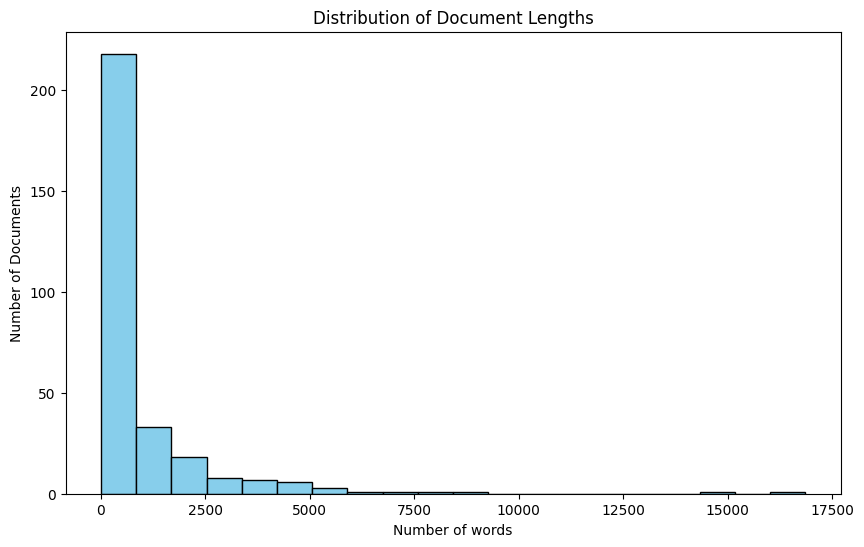

In [54]:
# Number of words per document
doc_lengths = [len(text.split()) for text in cleaned_texts]

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.hist(doc_lengths, bins=20, color='skyblue', edgecolor='black')
plt.title("Distribution of Document Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of Documents")
plt.show()

**INTERPRETATION:**
* The above graph shows a histogram with the title "Distribution of Document Lengths" which helps to visualise the word frequencies across the collection of documents.
* The histogram is a heavily right-skewed distribution, which means that majority of documents are short.
* Key observation is that most documents have fewer that 2500 words. More than 200 files comes under shortest word count category.

We now combine all the documents into one corpus. We define a function called get_word_frequencies which helps to tokenize the words and using counter, we determine the frequency of words. We then find top 20 words which is most frequent in the entire corpus. It then iterates through the results and prints the words and it's corresponding count.

In [55]:
from collections import Counter
from nltk.tokenize import word_tokenize

def get_word_frequencies(text, top_n=10):
    words = word_tokenize(text)
    word_freq = Counter(words)
    return word_freq.most_common(top_n)

# Combine all documents into one corpus
corpus_text = " ".join(cleaned_texts)

# Get top 20 words
word_freq = get_word_frequencies(corpus_text, top_n=20)

print("\nTop 20 most frequent words:")
for word, count in word_freq:
    print(f"{word}: {count}")


Top 20 most frequent words:
elect: 5040
vote: 4544
elector: 3534
parti: 3017
voter: 2511
candid: 2442
polit: 2224
senat: 2088
poll: 2073
aec: 1976
campaign: 1675
australian: 1607
volunt: 1568
feder: 1353
australia: 1326
one: 1300
state: 1294
hous: 1195
repres: 1178
system: 1158


**Interpretation:**

The output shows top 20 words which are most frequent in the entire corpus. It shows a relation between the election which takes place in Australia.

We now visualise word frequency using word cloud.

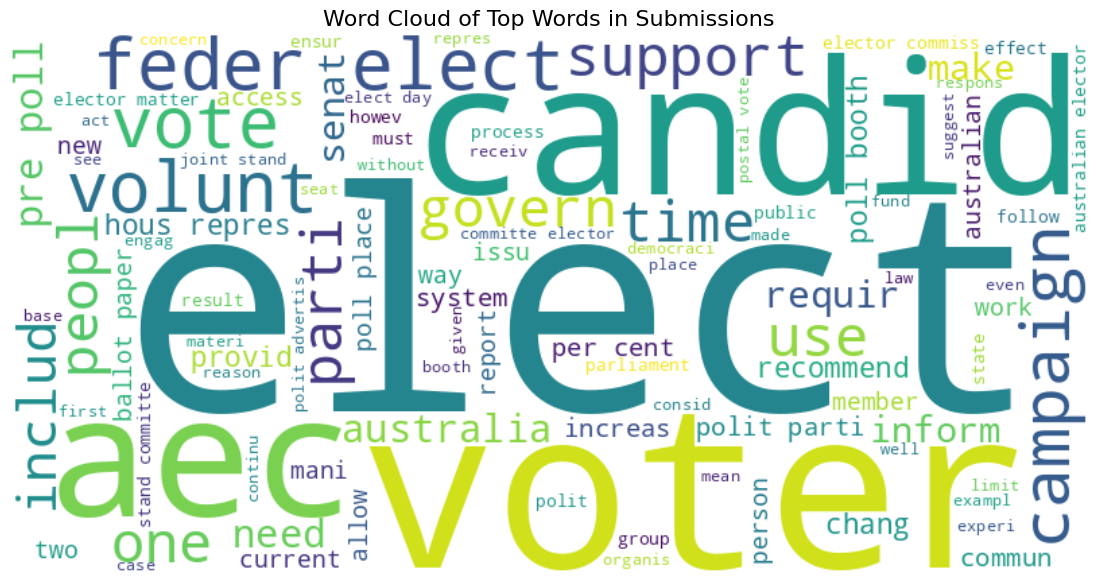

In [56]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Generate Word Cloud for top 100 words
wordcloud = WordCloud(
    width=800,            # width of the image
    height=400,           # height of the image
    max_words=100,        # show top 100 words
    background_color='white'  # clean background
).generate(corpus_text)

# Display the Word Cloud
plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud of Top Words in Submissions", fontsize=16)
plt.show()

**INTERPRETATION OF WORD CLOUD:**
* The visualisation helps to summarize most frequent words in an unorderly manner.
* From the image we can see that it talks about the election process taking place in Australia.
* The larget words shows the highest frequency. Words like "elect", "voter", "candid", "aec" are the most significant words.
* Words like "feder", "support", "australia", "poll", "people" are the other rellated words.
Clearly, we can see it talks about the Australian election campaigns and importance of voter and candidate in it.

## **VISUALISATION USING N-GRAMS**

## **We now visualise and see the patterns for top n-grams.**

In [59]:
from nltk import ngrams
from collections import Counter
from nltk.tokenize import word_tokenize

# Function to get top n-grams
def get_top_ngrams(tokenized_words, n=2, top_n=10):
    n_grams = ngrams(tokenized_words, n)
    ngram_freq = Counter(n_grams)
    return ngram_freq.most_common(top_n)

# Combine all cleaned texts into one string
corpus_text = " ".join(cleaned_texts)

# Tokenize the corpus
tokenized_words_cleaned = word_tokenize(corpus_text)

# Get top 10 bigrams
top_bigrams = get_top_ngrams(tokenized_words_cleaned, n=2, top_n=10)

# Get top 10 trigrams
top_trigrams = get_top_ngrams(tokenized_words_cleaned, n=3, top_n=10)

# Print results
print("Top 10 Bigrams:")
for bigram, count in top_bigrams:
    print(f"{' '.join(bigram)}: {count}")

print("\nTop 10 Trigrams:")
for trigram, count in top_trigrams:
    print(f"{' '.join(trigram)}: {count}")

Top 10 Bigrams:
feder elect: 954
pre poll: 638
hous repres: 540
poll booth: 536
polit parti: 514
per cent: 502
ballot paper: 447
poll place: 447
elector commiss: 397
elector matter: 394

Top 10 Trigrams:
joint stand committe: 334
committe elector matter: 331
stand committe elector: 325
australian elector commiss: 302
inquiri feder elect: 184
submiss joint stand: 167
truth polit advertis: 148
four year term: 130
commonwealth elector act: 109
elector commiss aec: 104


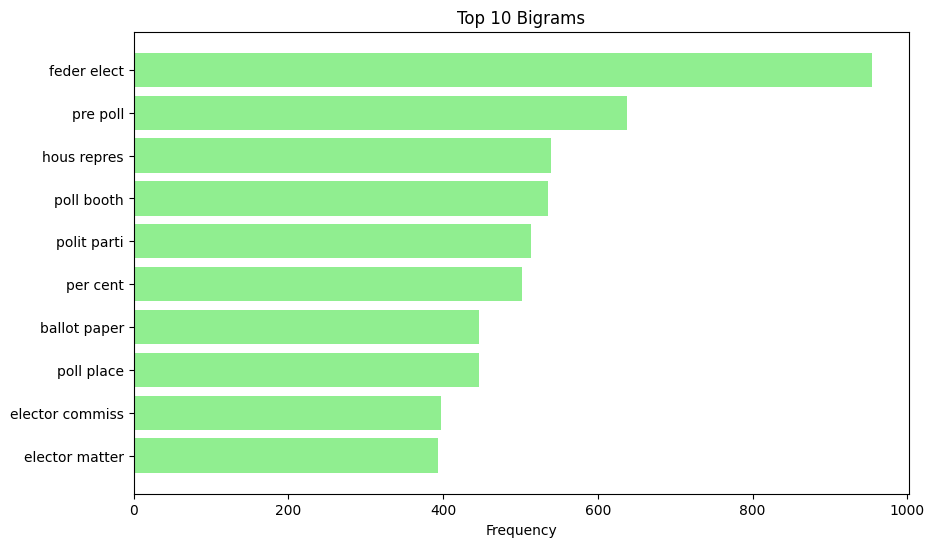

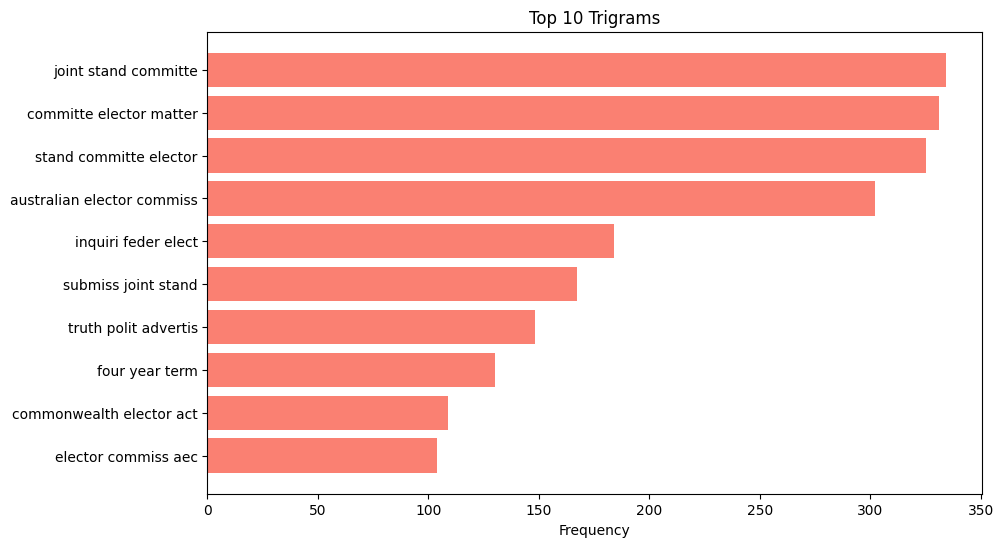

In [60]:
# Top bigrams bar chart
bigram_words = [' '.join(bigram) for bigram, _ in top_bigrams]
bigram_counts = [count for _, count in top_bigrams]

plt.figure(figsize=(10,6))
plt.barh(bigram_words[::-1], bigram_counts[::-1], color='lightgreen')
plt.title("Top 10 Bigrams")
plt.xlabel("Frequency")
plt.show()

# Top trigrams bar chart
trigram_words = [' '.join(trigram) for trigram, _ in top_trigrams]
trigram_counts = [count for _, count in top_trigrams]

plt.figure(figsize=(10,6))
plt.barh(trigram_words[::-1], trigram_counts[::-1], color='salmon')
plt.title("Top 10 Trigrams")
plt.xlabel("Frequency")
plt.show()

**INTERPRETATION FOR TOP 10 BIGRAMS:**
* The bar chart shows ten most frequent bigrams or two word combinations.
* The frequencies ranges from 200 to almost 1000 occurences.
* Below are the most frequent bigrams in order of their occurences:

Top 10 Bigrams:
1. feder elect: 954 occurences
2. pre poll: 638 occurences
3. hous repres: 540 occurences
4. poll booth: 536 occurences
5. polit parti: 514 occurences
6. per cent: 502 occurences
7. ballot paper: 447 occurences
8. poll place: 447 occurences
9. elector commiss: 397 occurences
10. elector matter: 394 occurences


**INTERPRETATION FOR TOP 10 TRIGRAMS:**
* The bar chart shows ten most frequent trigrams or three word combinations.
* The frequencies ranges from 100 to almost 350 occurences.
* Below are the most frequent trigrams in order of their occurences:

Top 10 Trigrams:
1. joint stand committe: 334 occurences
2. committe elector matter: 331 occurences
3. stand committe elector: 325 occurences
4. australian elector commiss: 302 occurences
5. inquiri feder elect: 184 occurences
6. submiss joint stand: 167 occurences
7. truth polit advertis: 148 occurences
8. four year term: 130 occurences
9. commonwealth elector act: 109 occurences
10. elector commiss aec: 104 occurences

##**3.2. TOPIC MODELING**

## **3.2.1. TF-IDF VECTORIZER:**

# **METHOD DESCRIPTION:**
* TF-IDF (Term Frequency-Inverse Document Frequency) is a numerical statistics that shows how important a word is in a document compared to a corpus.
* TF stand for "Term Frequency": It shows how many times a word shows up in a document.
* IDF stands for "inverse document frequency": It penalizes words that are common in a lot of documents.

A high TF-IDF score means that a word is common in one document but not in the whole corpus. This makes it useful for finding unique terms.

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import numpy as np

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(max_df=0.8, min_df=2, max_features=1000)
# max_df=0.8 ignores very common words, min_df=2 ignores words appearing in only 1 doc
# max_features limits to 1000 words for simplicity

# Fit and transform the cleaned texts
tfidf_matrix = tfidf_vectorizer.fit_transform(cleaned_texts)

# Get feature names (words)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Convert to DataFrame for easier handling
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)

# View top TF-IDF words for the whole corpus
# Sum TF-IDF scores across all documents
tfidf_sums = tfidf_df.sum(axis=0)
top_tfidf_words = tfidf_sums.sort_values(ascending=False).head(20)
print("Top 20 TF-IDF words in the corpus:")
print(top_tfidf_words)

Top 20 TF-IDF words in the corpus:
vote          29.474412
volunt        29.380215
poll          25.356840
parti         22.122231
voter         21.998342
candid        21.519796
booth         19.254833
campaign      16.898651
polit         15.990659
aec           15.786267
senat         12.492250
day           11.646880
pre           11.497691
australian    11.256753
feder         11.254216
peopl         11.131341
behaviour     10.777312
committe      10.392780
australia     10.295913
support        9.963921
dtype: float64


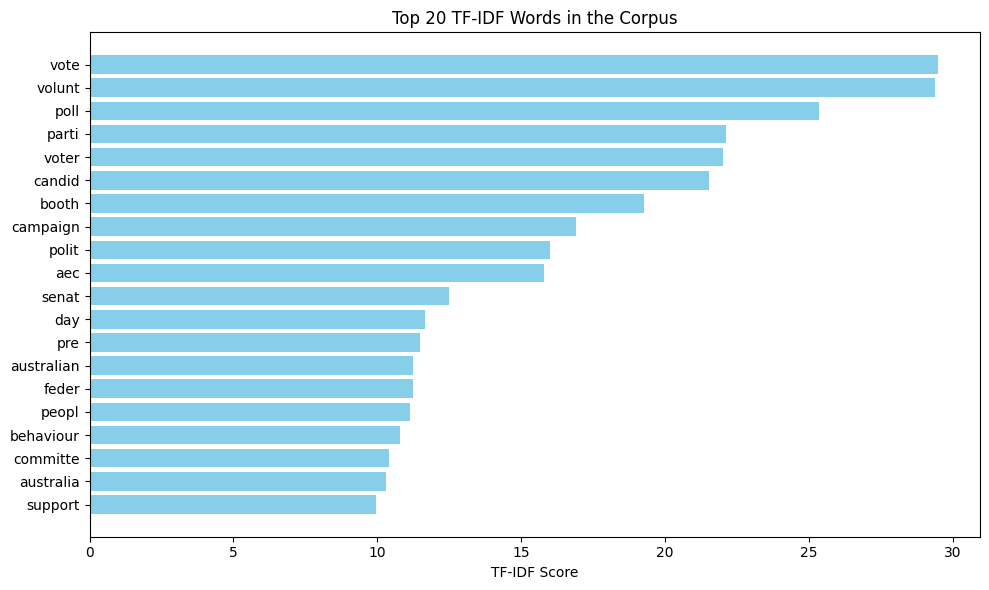

In [62]:
import matplotlib.pyplot as plt

# Get top 20 TF-IDF words (already computed)
top_n = 20
top_words = top_tfidf_words.head(top_n)
words = top_words.index
scores = top_words.values

# Create horizontal bar chart
plt.figure(figsize=(10,6))
plt.barh(words[::-1], scores[::-1], color='skyblue')  # reverse for highest on top
plt.xlabel('TF-IDF Score')
plt.title(f'Top {top_n} TF-IDF Words in the Corpus')
plt.tight_layout()
plt.show()

**INTERPRETATION:**
* Words such as "vote," "volunt," "poll," "voter," and "parti" come up a lot in the corpus, but not in every document.
* These are very important for the 2025 federal election submissions because they cover things like voting, political parties, polling, and volunteers.
* Words such as "campaign," "aec" (Australian Electoral Commission), and "candid" also get high scores, which shows that the text is mostly about elections, candidates, and how they work.

# **3.2.2. LDA Modeling**

### **METHOD DESCRIPTION:**
* Latent Dirichlet Allocation (LDA) is a probabilistic model that finds hidden topics in a group of documents.
* Every document is made up of different topics, and each topic is made up of different words.
* For LDA, we apply the following steps:

1.  We tokenize text into words.
2.  Make a dictionary that links words to IDs.
3. Change documents into a bag-of-words (BoW) format.
4. We provide LDA a certain number of topics (num_topics) to work with.





In [66]:
# Install gensim and pyLDAvis
!pip install --quiet gensim pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 64.8 MB/s eta 0:00:00


In [67]:
from gensim.corpora import Dictionary
from gensim.models.ldamodel import LdaModel

# Tokenize each cleaned text (documents)
tokenized_texts = [word_tokenize(text) for text in cleaned_texts]

# Create a Gensim dictionary from tokenized texts
dictionary = Dictionary(tokenized_texts)

# Filter extremes (optional but recommended)
dictionary.filter_extremes(no_below=2, no_above=0.5, keep_n=10000)  # remove very rare/common words

# Convert tokenized texts to bag-of-words corpus
corpus = [dictionary.doc2bow(text) for text in tokenized_texts]

In [69]:
# Train LDA model
num_topics = 5
lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    random_state=42,
    passes=10,   # number of passes through the corpus
    alpha='auto',
    per_word_topics=True
)

# Print topics
for idx, topic in lda_model.print_topics(-1):
    print(f"Topic {idx+1}: {topic}\n")

Topic 1: 0.021*"e" + 0.011*"n" + 0.009*"democraci" + 0.008*"p" + 0.007*"er" + 0.007*"labor" + 0.007*"parliament" + 0.007*"mp" + 0.007*"u" + 0.006*"fund"

Topic 2: 0.008*"pre" + 0.007*"behaviour" + 0.005*"intimid" + 0.005*"aggress" + 0.004*"centr" + 0.004*"brethren" + 0.004*"church" + 0.004*"hand" + 0.004*"group" + 0.004*"person"

Topic 3: 0.006*"access" + 0.006*"inform" + 0.005*"media" + 0.005*"requir" + 0.005*"advertis" + 0.005*"behaviour" + 0.005*"recommend" + 0.004*"materi" + 0.004*"act" + 0.004*"report"

Topic 4: 0.027*"ppvc" + 0.017*"nsw" + 0.012*"divis" + 0.011*"prefer" + 0.009*"vic" + 0.009*"senat" + 0.009*"total" + 0.009*"count" + 0.008*"ballot" + 0.007*"valu"

Topic 5: 0.023*"senat" + 0.012*"hous" + 0.010*"repres" + 0.010*"per" + 0.009*"year" + 0.009*"system" + 0.008*"parliament" + 0.007*"term" + 0.007*"cent" + 0.006*"seat"



In [70]:
import pyLDAvis.gensim_models as gensimvis
import pyLDAvis

# Prepare visualization
lda_vis = gensimvis.prepare(lda_model, corpus, dictionary)

# Display interactive visualization
pyLDAvis.display(lda_vis)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### **INTERPRETATION:**
Topic 1: Democracy, Parliament, Labor
* These words suggest about the political party and members of the parliament.
* In general, Topic 1 covers talks about the electoral system and how well parties represent their members.

Topic 2: pre, behaviour, intimid, aggress, centr, brethren, church, hand, group, person
* These words suggest religious aggression and voter behaviour.
* Words like behaviour, intimid, and aggress points to conversations about scaring voters or running aggressive campaigns.

Topic 3: access, inform, media, requir, advertis, behaviour, recommend, materi, act, report
* These words suggest about media involvement and election materials.
* This can also suggest how voters gets to know about the information related to elections.

Topic 4: ppvc, nsw, divis, prefer, vic, senat, total, count, ballot, valu
* This topic suggests the voting process, counting the votes, and the different parts of the election.
* These words shows about the logistics of elections and how election works.

Topic 5: senat, hous, repres, per, year, system, parliament, term, cent, seat
* These words suggests about structure of a parliament.
* Most likely talks about the overall electoral system and how well the legislature represents the people.

#**4. CONCLUSION**

Analysis of the 2025 Australian Federal Election submissions uncovers distinct patterns and apprehensions among voters and stakeholders.
The main findings show that people are very interested in issues like how easy it is for voters to get to the polls, how political volunteers act, how campaign materials are used in public places, and the overall fairness and honesty of the election process.

Topic modelling and word frequency analysis show that submissions often talk about voter experience, election procedures, political parties, and local polling issues. The prevalence of terms associated with intimidation, information access, and electoral administration underscores the significance of protecting democratic engagement and guaranteeing informed, equitable voting.

Answering to our question:What problems make it hard to vote and run elections?
Factor like voter confusion because of different pre-poll procedures, unclear instructions that led to informal or miscast votes, volunteers acting inappropriately or interfering with the campaign at polling places, and some communities not being able to easily get to polling places.

Based on these results, the next steps could be: making it easier for people to vote before the election to better manage voter flow, improving volunteer training to stop intimidation, looking over where campaign materials are placed.
Also, ongoing monitoring and data-driven assessment of voter experiences can help shape policy changes that make democracy more open and encourage more people to vote.
In general, this study shows that automated text analysis can give useful information that can help make evidence-based changes to how elections are run.